In [ ]:
from pathlib import Path

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "data" / "raw" / "train.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate data/raw/train.csv from the current directory")

RAW = PROJECT_ROOT / "data" / "raw"
PROCESSED = PROJECT_ROOT / "data" / "processed"

In [ ]:
import pandas as pd

df_train = pd.read_csv(RAW / "train.csv")
df_test = pd.read_csv(RAW / "test.csv")

required_columns = {"prompt", "essay", "evaluation", "band"}
for split_name, frame in (("train", df_train), ("test", df_test)):
    missing_columns = required_columns.difference(frame.columns)
    if missing_columns:
        raise ValueError(f"{split_name} data is missing required columns: {sorted(missing_columns)}")

all_data = pd.concat(
    [df_train.assign(split="train"), df_test.assign(split="test")],
    
    ignore_index=True,
)
all_data_source = all_data.copy()
print(f"Train rows: {len(df_train):,}; test rows: {len(df_test):,}; combined: {len(all_data):,}")
all_data.head()

Train rows: 9,833; test rows: 491; combined: 10,324


,Unnamed: 0,prompt,essay,evaluation,band,split
0,0,Interviews form the basic criteria for most la...,It is believed by some experts that the tradit...,**Task Achievement: [7]**\nThe essay effective...,7.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train
1,1,Interviews form the basic selecting criteria f...,Nowadays numerous huge firms allocate an inter...,**Task Achievement:** 5.0\n- The candidate has...,5.0\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train
2,2,Interview form the basic selection criteria fo...,The interview section is the most vital part o...,## Task Achievement:\n- The candidate has effe...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train
3,3,Interviews form the basic selection criteria f...,It is argued that the best method to recruit e...,## Task Achievement:\n- The candidate has adeq...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train
4,4,Interviews from the basic selecting criteria f...,Nowadays many companies conduct interviews bef...,**Task Achievement:**\n\nThe essay adequately ...,4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train


In [ ]:
print("Rows by split:")
print(all_data["split"].value_counts().reindex(["train", "test"]))

print("\nMissing values by column:")
display(all_data.isna().sum().to_frame("missing"))

print("Exact duplicate rows (excluding the split marker):")
print(all_data.drop(columns="split").duplicated().sum())

print("Repeated essay rows:")
print(all_data["essay"].duplicated().sum())

print("\nBlank or whitespace-only strings by text column:")
for column in all_data.select_dtypes(include=["object", "string"]).columns:
    blank_count = all_data[column].astype("string").str.strip().eq("").fillna(False).sum()
    print(f"{column}: {blank_count}")

Rows by split:
split
train    9833
test      491
Name: count, dtype: int64

Missing values by column:


,missing
Unnamed: 0,0
prompt,0
essay,0
evaluation,0
band,0
split,0


Exact duplicate rows (excluding the split marker):
0
Repeated essay rows:
1339

Blank or whitespace-only strings by text column:
prompt: 0
essay: 0
evaluation: 0
band: 0
split: 0


In [ ]:
#Kiểm tra các bài luận trùng có bị gán nhiều mức điểm khác nhau không
duplicate_check = (
    all_data.groupby("essay")
    .agg(
        so_ban_ghi=("essay", "size"),
        so_band_khac_nhau=("band", "nunique")
    )
    .query("so_ban_ghi > 1")
    .reset_index()
    .sort_values("so_ban_ghi", ascending=False)
)

print("Số nhóm bài luận trùng:", len(duplicate_check))

print(
    "Số nhóm có nhiều mức điểm:",
    (duplicate_check["so_band_khac_nhau"] > 1).sum()
)
duplicate_check

Số nhóm bài luận trùng: 1217
Số nhóm có nhiều mức điểm: 477


,essay,so_ban_ghi,so_band_khac_nhau
758,"Over the past decades, environmental problems ...",7,1
1079,There is an opinion that employers should not ...,5,4
179,Historical objects are precious items that car...,4,2
274,"In some countries, famous individuals often fe...",4,2
261,"In recent years, the increasing population has...",4,2
...,...,...,...
1180,"With globalization, nations are more interconn...",2,2
1181,"With the advancement in technology, robots tak...",2,2
1182,With the advancement of artificial intelligenc...,2,1
1183,With the advancement of modern technologies no...,2,1


In [ ]:
conflicting_essays = duplicate_check[
    duplicate_check["so_band_khac_nhau"] > 1
]["essay"]

if conflicting_essays.empty:
    print("No repeated essays have conflicting band labels.")
else:
    sample_essay = conflicting_essays.iloc[0]
    display(
        all_data.loc[
            all_data["essay"] == sample_essay,
            ["split", "prompt", "essay", "band", "evaluation"],
        ]
    )

,split,prompt,essay,band,evaluation
2618,train,Some people think that employers should not ca...,There is an opinion that employers should not ...,6\r\r\r\r\r\r\r\r,**Task Achievement:**\n\nThe candidate has eff...
2624,train,Some people think that employers should not ca...,There is an opinion that employers should not ...,6.5\r\r\r\r\r\r\r\r,### Task Achievement:\n- The candidate has eff...
3022,train,Some people think that employers should not ca...,There is an opinion that employers should not ...,6\r\r\r\r\r,## Task Achievement:\n- The candidate effectiv...
3028,train,Some people think that employers should not ca...,There is an opinion that employers should not ...,6.5\r\r\r\r\r,**Task Achievement:**\n\n- The essay effective...
9972,test,Some people think that employers should not ca...,There is an opinion that employers should not ...,6.5\r\r\r\r\r,**Task Achievement:**\n\n- The essay effective...


In [ ]:
#Chuẩn hóa band để so sánh chính xác
# Tạo cột điểm dạng số để kiểm tra, không sửa dữ liệu gốc
all_data_check = all_data.copy()

band_text = (
    all_data_check["band"].astype("string")
    .str.replace(r"[\r\n\t]", "", regex=True)
    .str.strip()
)
all_data_check["band_num"] = pd.to_numeric(
    band_text,
    errors="coerce"
)
all_data_check["band_comparison"] = all_data_check["band_num"].astype("string").fillna(band_text)

duplicate_check_num = (
    all_data_check.groupby("essay")
    .agg(
        so_ban_ghi=("essay", "size"),
        so_band_khac_nhau=("band_comparison", "nunique")
    )
    .query("so_ban_ghi > 1")
    .reset_index()
)

print(
    "Số nhóm bài luận trùng có nhiều mức điểm sau chuẩn hóa:",
    (duplicate_check_num["so_band_khac_nhau"] > 1).sum()
)

print(
    "Số nhãn band không hợp lệ (không tính nhãn đặc biệt '<4'):",
    (all_data_check["band_num"].isna() & band_text.ne("<4")).sum()
)
print("Số nhãn '<4':", band_text.eq("<4").sum())
all_data_check.loc[
    all_data_check["band_num"].isna() & band_text.ne("<4"),
    ["split", "band"],
].drop_duplicates()

Số nhóm bài luận trùng có nhiều mức điểm sau chuẩn hóa: 5
Số nhãn band không hợp lệ (không tính nhãn đặc biệt '<4'): 0
Số nhãn '<4': 612


,split,band


In [ ]:
# all_data = remaining_data
#Kiểm tra toàn bộ các dạng nhãn band
# Chuẩn hóa ký tự xuống dòng và khoảng trắng
# print(all_data.columns)
band_cleaned = (
    all_data["band"]
    .astype(str)
    .str.replace(r"[\r\n\t]", "", regex=True)
    .str.strip()
)

print("Các nhãn band sau khi loại ký tự thừa:")
display(band_cleaned.value_counts().to_frame("Số lượng"))

print("\nSố nhãn bắt đầu bằng '<':",
      band_cleaned.str.startswith("<").sum())

print("\nSố nhãn còn lại không phải số:",
      pd.to_numeric(band_cleaned, errors="coerce").isna().sum())

Các nhãn band sau khi loại ký tự thừa:


,Số lượng
band,
7,1434
6.5,1235
6,1201
7.5,1146
5,1083
5.5,1013
8,735
4.5,676
4,627



Số nhãn bắt đầu bằng '<': 612

Số nhãn còn lại không phải số: 612


In [ ]:
#Chuẩn hóa nhãn band cho cả all và test
import pandas as pd
def clean_band(series):
    return (
        series.astype(str)
        .str.replace(r"[\r\n\t+]", "", regex=True)
        .str.strip()
    )

all_data.loc[:,"band_clean"] = clean_band(all_data.loc[:,"band"])
# test["band_clean"] = clean_band(test["band"])

print("Phân bố nhãn band trong all_data:")
display(all_data["band_clean"].value_counts().sort_index().to_frame("Số lượng"))
# print("\nPhân bố nhãn band trong test:")
# display(test["band_clean"].value_counts().sort_index().to_frame("Số lượng"))

Phân bố nhãn band trong all_data:


,Số lượng
band_clean,
4,627
4.5,676
5,1083
5.0,1
5.5,1013
6,1201
6.5,1235
7,1434
7.5,1146


In [ ]:
#Chuẩn hóa định dạng nhãn điểm
def normalize_band(series):
    cleaned = clean_band(series)

    def normalize_one(value):
        if value == "<4":
            return "<4"

        try:
            number = float(value)
            return str(float(number)) if number.is_integer() else str(number)
        except ValueError:
            return value

    return cleaned.apply(normalize_one)


all_data.loc[:,"band_clean"] = normalize_band(all_data.loc[:,"band"])
# test["band_clean"] = normalize_band(test["band"])

print("Phân bố nhãn all_data sau chuẩn hóa:")
display(all_data.loc[:,"band_clean"].value_counts().sort_index().to_frame("Số lượng"))

# print("\nPhân bố nhãn test sau chuẩn hóa:")
# display(test["band_clean"].value_counts().sort_index().to_frame("Số lượng"))

print("\nTổng số mẫu all_data:", len(all_data))
# print("Tổng số mẫu test:", len(test))

Phân bố nhãn all_data sau chuẩn hóa:


,Số lượng
band_clean,
4.0,627
4.5,676
5.0,1084
5.5,1013
6.0,1201
6.5,1235
7.0,1434
7.5,1146
8.0,735



Tổng số mẫu all_data: 10324


In [ ]:
#chuẩn hóa, loại bỏ những ký tự thừa ở essay và evaluation
import re
import unicodedata

def clean_text(text: str) -> str:
    if not isinstance(text, str) or not text.strip():
        return ""

    # 1. Chuẩn hóa Unicode (NFKC) & đồng nhất dấu nháy/gạch ngang
    text = unicodedata.normalize('NFKC', text)
    text = re.sub(r"[’‘`]", "'", text)        # Chuyển smart apostrophe về nháy đơn chuẩn
    text = re.sub(r"[“”]", '"', text)        # Chuyển smart quotes về nháy đôi chuẩn
    text = re.sub(r"[—–]", "-", text)         # Đồng nhất các loại dấu gạch ngang (em-dash, en-dash)

    # 2. Xóa các ký tự không hợp lệ (emoji, ký hiệu toán học lạ,...)
    # Giữ lại: chữ cái, số, khoảng trắng, các dấu câu cơ bản: . , ? ! : ; ' " - ( ) % $
    text = re.sub(r"[^\w\s\.,?!\x27\"\-:;()%\$]", "", text)

    # 3. Sửa lỗi khoảng trắng quanh dấu câu
    # 3a. Xóa khoảng trắng thừa TRƯỚC dấu câu (ví dụ: "good ." -> "good.")
    text = re.sub(r"\s+([.,?!:;])", r"\1", text)
    
    # 3b. Thêm khoảng trắng SAU dấu câu nếu dính liền với chữ cái (ví dụ: "however,some" -> "however, some")
    text = re.sub(r"([.,?!:;])([A-Za-z])", r"\1 \2", text)
    
    # 3c. Xử lý khoảng trắng thừa quanh dấu ngoặc đơn
    text = re.sub(r"\(\s+", "(", text)
    text = re.sub(r"\s+\)", ")", text)

    # 4. Chuẩn hóa dòng và khoảng trắng (Whitespace cleanup)
    text = re.sub(r"[\t\r]", " ", text)        # Chuyển tab và \r thành khoảng trắng
    text = re.sub(r"[ ]{2,}", " ", text)       # Thu gọn nhiều khoảng trắng liên tiếp trên cùng 1 dòng
    text = re.sub(r" *\n *", "\n", text)       # Xóa khoảng trắng thừa ở đầu/cuối mỗi dòng
    text = re.sub(r"\n{3,}", "\n\n", text)     # Thu gọn 3+ dòng trống liên tiếp thành 2 dòng (phân chia đoạn văn)

    return text.strip()
# display(all_data)
all_data_copy = all_data.copy()
#loại bỏ những bài có essay, prompt, evaluation giống nhau
all_data_copy["prompt_clean"] = all_data_copy["prompt"].map(clean_text)
all_data_copy[["essay", "evaluation"]] = all_data_copy[["essay", "evaluation"]].map(clean_text)

remaining_data = all_data_copy.drop_duplicates(
    subset=["prompt_clean", "essay", "evaluation"], keep="first"
)
print(f"Trước khi xóa: {len(all_data_copy)}")
print(f'Sau khi xóa {len(remaining_data)}')
print(f'Số dòng bị loại: {len(all_data_copy) - len(remaining_data)}')
print(f'Tỉ lệ bị loại: {(len(all_data_copy) - len(remaining_data)) / len(all_data_copy):.2%}')

Trước khi xóa: 10324
Sau khi xóa 9833
Số dòng bị loại: 491
Tỉ lệ bị loại: 4.76%


In [ ]:
#những bài giống nhau nhưng nhiều band điểm khác nhau
# tính khoảng cách giữa điểm lớn nhất và điểm nhỏ nhất, <= 1.0 -> lấy trung bình, > 1.0 -> bỏ do độ lệch quá lớn
import numpy as np
import math

all_data = remaining_data

def round_ielts(score):
    if pd.isna(score):
        return score
    
    frac, integral = math.modf(score)
    if frac < 0.25:
        return integral + 0.0
    elif frac < 0.75:
        return integral + 0.5
    else:
        return integral + 1.0
essay_diff_scores = all_data.groupby('essay').agg(
    unique_score_count=('band_clean', 'nunique'),
    all_scores=('band_clean', lambda x: list(x.unique()))
).reset_index()
essay_diff_scores = essay_diff_scores[essay_diff_scores['unique_score_count'] > 1]
# print(type(essay_diff_scores.loc[:,'all_scores']))
for idx, row in essay_diff_scores.iterrows():
    if ('<4' in row['all_scores']):
        continue
    scores = np.array(row['all_scores']).astype(float)
    
    if len(scores) == 2:
        distance = np.max(scores) - np.min(scores)
        if (distance <= 1.0):
            essay_diff_scores.at[idx,'all_scores'] = round_ielts(np.mean(scores))
        else:
            essay_diff_scores.at[idx,'all_scores'] = np.nan
    else:
        essay_diff_scores.at[idx,'all_scores'] = np.median(scores)

essay_diff_scores_copy = essay_diff_scores.copy()
has_less_than_score = essay_diff_scores_copy["all_scores"].map(
    lambda scores: isinstance(scores, list)
    and any("<" in str(score) for score in scores)
)
essay_diff_scores_copy["band_clean"] = essay_diff_scores_copy["all_scores"].map(
    lambda score: (
        pd.NA if isinstance(score, list) or pd.isna(score)
        else str(int(score)) if float(score).is_integer()
        else str(float(score))
    )
)
# essay_diff_scores.loc[has_less_than_score, "band_clean"] = pd.NA
score_lookup = essay_diff_scores_copy.loc[~has_less_than_score].set_index("essay")["band_clean"]
update_mask = all_data["essay"].isin(score_lookup.index)
all_data.loc[update_mask, "band_clean"] = all_data.loc[update_mask, "essay"].map(score_lookup)

preserved_essay_count = int(has_less_than_score.sum())
preserved_essay_label = "essay" if preserved_essay_count == 1 else "essays"
print(
    f"Updated band_clean for {int(update_mask.sum())} rows across "
    f"{len(score_lookup):,} essays; preserved {preserved_essay_count} "
    f"{preserved_essay_label} with a '<' score label."
)
all_data = all_data.dropna()
all_data = all_data.drop_duplicates(subset=['essay', 'evaluation', 'band_clean'])
print('Sau khi loại bỏ trùng lặp ở essay, evaluation và band_clean:')
all_data

Updated band_clean for 12 rows across 5 essays; preserved 1 essay with a '<' score label.
Sau khi loại bỏ trùng lặp ở essay, evaluation và band_clean:


,Unnamed: 0,prompt,essay,evaluation,band,split,band_clean,prompt_clean
0,0,Interviews form the basic criteria for most la...,It is believed by some experts that the tradit...,Task Achievement: 7\nThe essay effectively add...,7.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,7.5,Interviews form the basic criteria for most la...
1,1,Interviews form the basic selecting criteria f...,Nowadays numerous huge firms allocate an inter...,Task Achievement: 5.0\n- The candidate has eff...,5.0\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,5.0,Interviews form the basic selecting criteria f...
2,2,Interview form the basic selection criteria fo...,The interview section is the most vital part o...,Task Achievement:\n- The candidate has effecti...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,5.5,Interview form the basic selection criteria fo...
3,3,Interviews form the basic selection criteria f...,It is argued that the best method to recruit e...,Task Achievement:\n- The candidate has adequat...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,5.5,Interviews form the basic selection criteria f...
4,4,Interviews from the basic selecting criteria f...,Nowadays many companies conduct interviews bef...,Task Achievement:\n\nThe essay adequately addr...,4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,4.0,Interviews from the basic selecting criteria f...
...,...,...,...,...,...,...,...,...
9828,9828,Nations should spend more money on skills and ...,"These days, many countries use a huge amount o...",Task Achievement:\nThe essay addresses the tas...,8,train,8.0,Nations should spend more money on skills and ...
9829,9829,Nations should spend more money on skills and ...,Skills are required in order to achieve succes...,Task Achievement:\n- The candidate has not eff...,<4,train,<4,Nations should spend more money on skills and ...
9830,9830,Nations should spend more money on skills and ...,There is a contradictory view among the people...,Task Achievement:\n- The essay adequately addr...,7,train,7.0,Nations should spend more money on skills and ...
9831,9831,Nations should spend more money on skills and ...,Many today feel that countries should prioriti...,Task Achievement:\n- The candidate has effecti...,7.5,train,7.5,Nations should spend more money on skills and ...


Thống kê độ dài bài luận (số từ):


,count,mean,std,min,25%,50%,75%,max
word_count,9826.0,293.031956,57.922542,50.0,263.0,289.0,322.0,1557.0


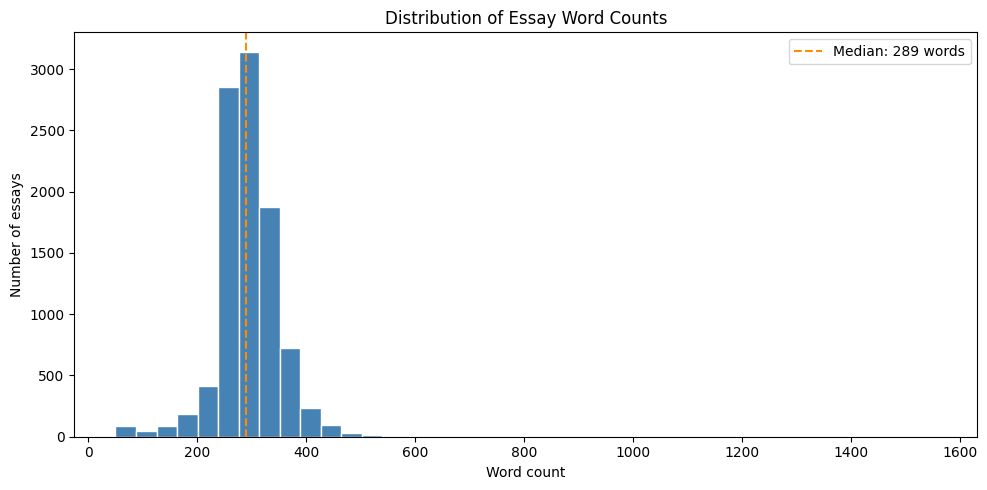


5 bài luận ngắn nhất:


,essay,word_count,band_clean
1047,"Nowdays, abundant of old age people are experi...",50,<4
1999,"From my perspective, I contend that the increa...",50,<4
8600,"In this twenty-first century, I suggest that t...",51,<4
4402,"In this twenty-first century, I suggest that t...",51,<4
4445,It is undeniable that school plays a vital rol...,52,<4



5 bài luận dài nhất:


,essay,word_count,band_clean
1610,The automotive industry is undergoing one of t...,1557,4.5
2846,Global warming is not a prediction. It is happ...,792,4.0
1716,"In this contemporary era, every citizen of a c...",678,6.0
5924,Nobody can deny the growing economic progress ...,590,5.0
8477,It is argued by many people that the increasin...,578,5.0


In [ ]:
#Khám phá độ dài bài luận
# Tạo bản sao để phân tích, không sửa dữ liệu gốc
all_data_eda = all_data.copy()
all_data_eda = all_data_eda[all_data_eda["essay"] != 'NAME?']
# Đếm số từ trong mỗi bài luận
all_data_eda["word_count"] = (
    all_data_eda["essay"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

print("Thống kê độ dài bài luận (số từ):")
display(all_data_eda["word_count"].describe().to_frame().T)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(all_data_eda["word_count"], bins=40, color="steelblue", edgecolor="white")
plt.axvline(
    all_data_eda["word_count"].median(),
    color="darkorange",
    linestyle="--",
    label=f'Median: {all_data_eda["word_count"].median():.0f} words',
)
plt.title("Distribution of Essay Word Counts")
plt.xlabel("Word count")
plt.ylabel("Number of essays")
plt.legend()
plt.tight_layout()
plt.show()

print("\n5 bài luận ngắn nhất:")
display(
    all_data_eda[["essay", "word_count", "band_clean"]]
    .sort_values("word_count")
    .head(5)
)

print("\n5 bài luận dài nhất:")
display(
    all_data_eda[["essay", "word_count", "band_clean"]]
    .sort_values("word_count", ascending=False)
    .head(5)
)
# all_data_eda[all_data_eda['band_clean'] == '<4'].count()


In [ ]:
lower_four_idx = all_data_eda[all_data_eda['band_clean'] == '<4'].index

# print(len(lower_four))
for idx in lower_four_idx:
    evaluation = all_data_eda.loc[idx, 'evaluation']
    # print(evaluation)
    numbers = re.findall(r"\d+\.?\d*", evaluation)
    numbers = [float(x) for x in numbers]
    if numbers:
        if len(numbers) > 4:
            # print(numbers)
            # print(evaluation)
            numbers = numbers[:4]
        if np.mean(numbers) == 0:
            numbers = 1
            # print(numbers)
            # print(evaluation)
        all_data_eda.loc[idx, 'band_clean'] = round(np.mean(numbers) * 2) / 2
    else:
        all_data_eda.loc[idx, 'band_clean'] = np.nan
        
all_data_eda['band_clean'] = all_data_eda['band_clean'].astype(float)
display(all_data_eda)

,Unnamed: 0,prompt,essay,evaluation,band,split,band_clean,prompt_clean,word_count
0,0,Interviews form the basic criteria for most la...,It is believed by some experts that the tradit...,Task Achievement: 7\nThe essay effectively add...,7.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,7.5,Interviews form the basic criteria for most la...,357
1,1,Interviews form the basic selecting criteria f...,Nowadays numerous huge firms allocate an inter...,Task Achievement: 5.0\n- The candidate has eff...,5.0\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,5.0,Interviews form the basic selecting criteria f...,308
2,2,Interview form the basic selection criteria fo...,The interview section is the most vital part o...,Task Achievement:\n- The candidate has effecti...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,5.5,Interview form the basic selection criteria fo...,401
3,3,Interviews form the basic selection criteria f...,It is argued that the best method to recruit e...,Task Achievement:\n- The candidate has adequat...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,5.5,Interviews form the basic selection criteria f...,358
4,4,Interviews from the basic selecting criteria f...,Nowadays many companies conduct interviews bef...,Task Achievement:\n\nThe essay adequately addr...,4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r,train,4.0,Interviews from the basic selecting criteria f...,215
...,...,...,...,...,...,...,...,...,...
9828,9828,Nations should spend more money on skills and ...,"These days, many countries use a huge amount o...",Task Achievement:\nThe essay addresses the tas...,8,train,8.0,Nations should spend more money on skills and ...,308
9829,9829,Nations should spend more money on skills and ...,Skills are required in order to achieve succes...,Task Achievement:\n- The candidate has not eff...,<4,train,4.0,Nations should spend more money on skills and ...,240
9830,9830,Nations should spend more money on skills and ...,There is a contradictory view among the people...,Task Achievement:\n- The essay adequately addr...,7,train,7.0,Nations should spend more money on skills and ...,261
9831,9831,Nations should spend more money on skills and ...,Many today feel that countries should prioriti...,Task Achievement:\n- The candidate has effecti...,7.5,train,7.5,Nations should spend more money on skills and ...,308


Bảng phân bố điểm:


,Số lượng
band_clean,
0.0,0
0.5,1
1.0,31
1.5,15
2.0,123
2.5,81
3.0,85
3.5,19
4.0,796


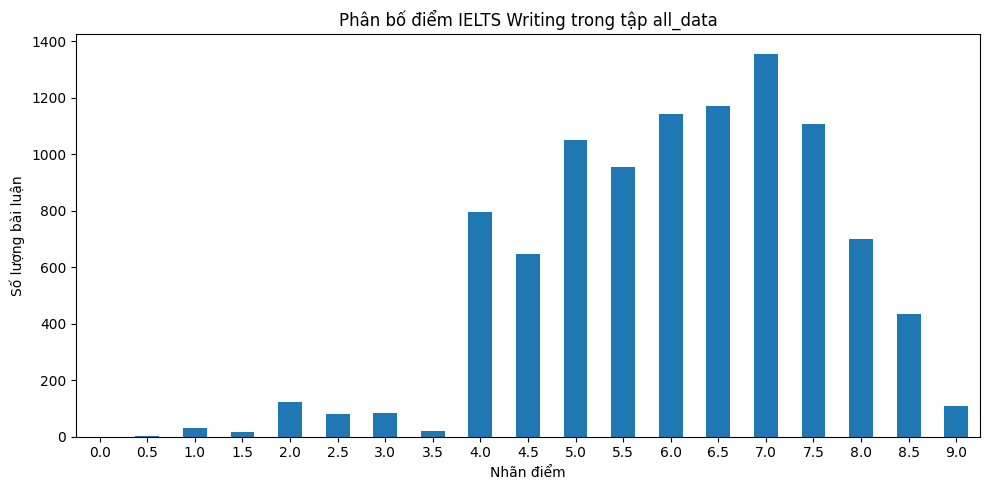

In [ ]:
#Khám phá phân bố điểm trong tập train
import matplotlib.pyplot as plt

band_counts = all_data_eda["band_clean"].value_counts()

# Sắp xếp nhãn theo thứ tự điểm
band_order = ["0", "0.5", "1.0", "1.5", "2.0", "2.5", "3.0", "3.5", "4", "4.5", "5", "5.5",
              "6", "6.5", "7", "7.5", "8", "8.5", "9"]
band_order = [float(x) for x in band_order]
band_counts = band_counts.reindex(band_order, fill_value=0)

print("Bảng phân bố điểm:")
display(band_counts.to_frame("Số lượng"))

plt.figure(figsize=(10, 5))
band_counts.plot(kind="bar")
plt.title("Phân bố điểm IELTS Writing trong tập all_data")
plt.xlabel("Nhãn điểm")
plt.ylabel("Số lượng bài luận")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()